# Scheduling playground
Run all cells, then change the instance, seeds, and search budget below. Timings exclude charts and exports.


In [13]:
from pathlib import Path
import os, sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "flexo/example.json").exists())
os.chdir(root)
if str(root) not in sys.path: sys.path.insert(0, str(root))
from experiments.playground import run, timeline
from IPython.display import display

INSTANCE = "instances/validation/N100_K3_rho1.5_rep00.json"
# Or: "flexo/example.json", "instances/smac/heldout/N50_carryover_00.json"
SEEDS = [42, 43, 44]
PARAMETERS = {"evaluations": 10000000, "starts": 10}
# Set PARAMETERS=None for automatic size profiles / baseline defaults.
THREADS = 10


In [14]:
rows, best = run(INSTANCE, seeds=SEEDS, parameters=PARAMETERS, threads=THREADS,
                 output_dir="results/notebook")


seed=42  fitness=11.00388  ink=0  flow=18.340h  makespan=40.469h  wall=980.69ms  horizons=3
seed=43  fitness=10.99417  ink=0  flow=18.324h  makespan=40.367h  wall=1037.73ms  horizons=3
seed=44  fitness=11.20821  ink=0  flow=18.680h  makespan=40.733h  wall=1018.80ms  horizons=3
Mean fitness: 11.06875 | Median wall: 1018.80 ms | Best seed: 43


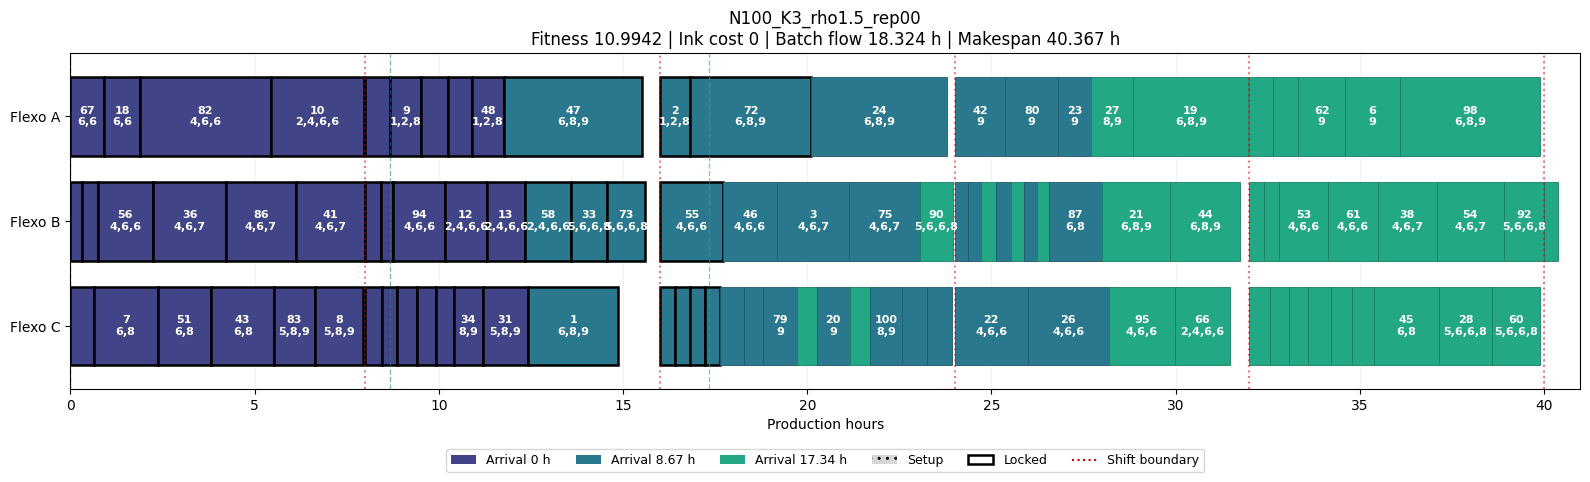

In [15]:
import json
import matplotlib.pyplot as plt
data = json.loads(Path(INSTANCE).read_text())
fig = timeline(best, Path(INSTANCE).stem, now=data.get("now"))
fig.savefig("results/notebook/timeline.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)


In [16]:
# Inspect the complete timings and per-horizon metrics.
display(best.get("horizons", rows))
display(best["schedule"])


[{'now': 0.0,
  'fitness': 7.401473214285714,
  'movable_jobs': 33,
  'profile_size': None,
  'runtime': 0.2611410999670625},
 {'now': 8.67,
  'fitness': 9.293019642857143,
  'movable_jobs': 45,
  'profile_size': None,
  'runtime': 0.35816519998479635},
 {'now': 17.34,
  'fitness': 10.994171428571429,
  'movable_jobs': 55,
  'profile_size': None,
  'runtime': 0.41778339992742985}]

{'Flexo A': [{'id': '67',
   'quantity': 6166,
   'inks': [6, 6],
   'arrival_time': 0.0,
   'setup_start': 0.0,
   'start': 0.0,
   'completion': 0.9175595238095239,
   'ink_change_cost': -0.0,
   'locked': True},
  {'id': '18',
   'quantity': 6583,
   'inks': [6, 6],
   'arrival_time': 0.0,
   'setup_start': 0.9175595238095239,
   'start': 0.9175595238095239,
   'completion': 1.8971726190476192,
   'ink_change_cost': -0.0,
   'locked': True},
  {'id': '82',
   'quantity': 23826,
   'inks': [4, 6, 6],
   'arrival_time': 0.0,
   'setup_start': 1.8971726190476192,
   'start': 1.8971726190476192,
   'completion': 5.442708333333334,
   'ink_change_cost': -0.0,
   'locked': True},
  {'id': '10',
   'quantity': 16894,
   'inks': [2, 4, 6, 6],
   'arrival_time': 0.0,
   'setup_start': 5.442708333333334,
   'start': 5.442708333333334,
   'completion': 7.95669642857143,
   'ink_change_cost': -0.0,
   'locked': True},
  {'id': '17',
   'quantity': 4628,
   'inks': [8],
   'arrival_time': 0.0,
 